Clocked VAE - Manufacturing Attendance Pretraining

This notebook checks whether a public employee attendance dataset improves the Clocked VAE.

This experiment compares:

1. Clocked-only VAE
2. Manufacturing-pretrained VAE -> fine-tuned on Clocked

In [3]:
# libraries

import re
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)


PyTorch: 2.14.1


1. Load Clocked data

In [4]:
clocked_path = Path("unified_attendance_1250.csv")

if not clocked_path.exists():
    clocked_path = Path("/mnt/data/unified_attendance_1250.csv")

clocked = pd.read_csv(clocked_path)

clocked = clocked[
    clocked["fraud_label"].notna()
].copy()

clocked["fraud_label"] = clocked["fraud_label"].astype(int)

clocked["clock_in_at"] = pd.to_datetime(
    clocked["clock_in_at"],
    errors="coerce",
)

clocked = clocked.dropna(
    subset=["clock_in_at", "shift_hours", "employee_id"]
).copy()

print("Clocked labelled rows:", len(clocked))
print(clocked["fraud_label"].value_counts())


Clocked labelled rows: 1000
fraud_label
0    820
1    180
Name: count, dtype: int64


2. Split Clocked first

The split is created before calculating normal attendance patterns.

This helps avoid using information from the test set when building the training features.


In [5]:
train_df, test_df = train_test_split(
    clocked,
    test_size=0.30,
    random_state=SEED,
    stratify=clocked["fraud_label"],
)

normal_train = train_df[
    train_df["fraud_label"] == 0
].copy()

print("Normal Clocked training rows:", len(normal_train))
print("Clocked test rows:", len(test_df))
print("Test fraud rows:", int(test_df["fraud_label"].sum()))


Normal Clocked training rows: 574
Clocked test rows: 300
Test fraud rows: 54


3. Create shared attendance-behaviour features

The manufacturing company used a fixed 7:00 AM start time, while Clocked employees can have different normal start times.

Because of this, we do not use absolute clock time as the transfer feature.

Instead, both datasets are converted into four comparable behavioural features:

- deviation from normal shift duration
- deviation from normal start time
- tardy flag
- overtime flag

Values are clipped so a few extreme records do not dominate VAE training.


In [6]:
FEATURES = [
    "shift_deviation",
    "start_deviation",
    "tardy_flag",
    "overtime_flag",
]


def circular_minute_difference(value, reference):
    difference = value - reference
    return ((difference + 720) % 1440) - 720


def build_clocked_reference(normal_data):
    data = normal_data.copy()

    data["clock_minute"] = (
        data["clock_in_at"].dt.hour * 60
        + data["clock_in_at"].dt.minute
    )

    employee_reference = (
        data.groupby("employee_id")
        .agg(
            normal_start=("clock_minute", "median"),
            normal_shift=("shift_hours", "median"),
        )
        .to_dict("index")
    )

    global_reference = {
        "normal_start": float(data["clock_minute"].median()),
        "normal_shift": float(data["shift_hours"].median()),
    }

    return employee_reference, global_reference


employee_reference, global_reference = build_clocked_reference(
    normal_train
)


def clocked_features(data):
    rows = []

    for _, row in data.iterrows():
        reference = employee_reference.get(
            row["employee_id"],
            global_reference,
        )

        clock_minute = (
            row["clock_in_at"].hour * 60
            + row["clock_in_at"].minute
        )

        start_difference = circular_minute_difference(
            clock_minute,
            reference["normal_start"],
        )

        shift_difference = (
            float(row["shift_hours"])
            - reference["normal_shift"]
        )

        rows.append([
            np.clip(shift_difference / 4.0, -1.0, 1.0),
            np.clip(start_difference / 120.0, -1.0, 1.0),
            1.0 if start_difference > 15 else 0.0,
            1.0 if shift_difference > 0.5 else 0.0,
        ])

    return np.asarray(rows, dtype=np.float32)


X_clocked_train = clocked_features(normal_train)
X_clocked_test = clocked_features(test_df)
y_clocked_test = test_df["fraud_label"].to_numpy(dtype=int)

print("Clocked training shape:", X_clocked_train.shape)
print("Clocked test shape:", X_clocked_test.shape)


Clocked training shape: (574, 4)
Clocked test shape: (300, 4)


4. Load the public manufacturing dataset

In [7]:
manufacturing_path = Path("manufacturingdata3.xlsx")

if not manufacturing_path.exists():
    raise FileNotFoundError(
        "Put manufacturingdata3.xlsx in the same folder as this notebook."
    )

manufacturing = pd.read_excel(manufacturing_path)

print("Manufacturing rows:", len(manufacturing))
print("\nColumns:")
for column in manufacturing.columns:
    print("-", column)

display(manufacturing.head())


Manufacturing rows: 1560

Columns:
- employee number 
- Gender
- Age
- Day
- Punctuality in minutes 
- absent 
- # minutes worked today 
- Safety check


,employee number,Gender,Age,Day,Punctuality in minutes,absent,# minutes worked today,Safety check
0,782,female,44,21,-2.0,NaN,482.0,yes
1,783,female,46,21,NaN,NaN,607.0,yes
2,784,female,49,21,6.0,NaN,482.0,yes
3,785,male,38,21,-4.0,NaN,595.0,yes
4,786,female,70,21,-4.0,NaN,488.0,yes


5. Find the attendance columns

The public file is kept in its original research format.

This cell looks for the variables describing:

- minutes worked
- punctuality
- tardiness

The paper defines punctuality as minutes relative to the 7:00 AM start time: negative means early and positive means late.


In [8]:
def clean_name(value):
    return re.sub(
        r"[^a-z0-9]+",
        " ",
        str(value).lower(),
    ).strip()


column_lookup = {
    clean_name(column): column
    for column in manufacturing.columns
}


def find_column(exact_candidates, contains_candidates):
    for candidate in exact_candidates:
        cleaned = clean_name(candidate)
        if cleaned in column_lookup:
            return column_lookup[cleaned]

    for cleaned_name, original_name in column_lookup.items():
        if all(
            token in cleaned_name
            for token in contains_candidates
        ):
            return original_name

    return None


minutes_column = find_column(
    [
        "minutes worked exclude absence",
        "minutes worked",
        "minutesworked",
        "minutes_worked",
    ],
    ["minutes", "work"],
)

punctuality_column = find_column(
    ["punctuality"],
    ["punctual"],
)

tardiness_column = find_column(
    ["tardiness"],
    ["tard"],
)

print("Minutes worked column:", minutes_column)
print("Punctuality column:", punctuality_column)
print("Tardiness column:", tardiness_column)

if minutes_column is None:
    raise ValueError(
        "Could not automatically find the minutes-worked column. "
        "Check the printed column names above and set minutes_column manually."
    )

if punctuality_column is None and tardiness_column is None:
    raise ValueError(
        "Could not find punctuality or tardiness. "
        "Check the printed column names above and set the correct column manually."
    )


Minutes worked column: # minutes worked today 
Punctuality column: Punctuality in minutes 
Tardiness column: None


6. Convert manufacturing attendance into the shared feature space

In [9]:
external = manufacturing.copy()

external["minutes_worked_model"] = pd.to_numeric(
    external[minutes_column],
    errors="coerce",
)

external["shift_hours_model"] = (
    external["minutes_worked_model"] / 60.0
)

if punctuality_column is not None:
    external["start_deviation_minutes"] = pd.to_numeric(
        external[punctuality_column],
        errors="coerce",
    )
else:
    # tardiness has no negative early-arrival values
    external["start_deviation_minutes"] = pd.to_numeric(
        external[tardiness_column],
        errors="coerce",
    )

external = external.dropna(
    subset=[
        "shift_hours_model",
        "start_deviation_minutes",
    ]
).copy()

# remove impossible or obviously non-work rows
external = external[
    external["shift_hours_model"].between(1, 18)
].copy()

normal_external_shift = float(
    external["shift_hours_model"].median()
)

external["shift_deviation"] = np.clip(
    (
        external["shift_hours_model"]
        - normal_external_shift
    ) / 4.0,
    -1.0,
    1.0,
)

external["start_deviation"] = np.clip(
    external["start_deviation_minutes"] / 120.0,
    -1.0,
    1.0,
)

external["tardy_flag"] = (
    external["start_deviation_minutes"] > 15
).astype(float)

external["overtime_flag"] = (
    external["shift_hours_model"]
    > normal_external_shift + 0.5
).astype(float)

X_manufacturing = external[FEATURES].to_numpy(
    dtype=np.float32
)

print("Manufacturing rows used:", len(external))
print("Median manufacturing shift hours:", round(normal_external_shift, 2))
print("Feature shape:", X_manufacturing.shape)

display(
    external[
        [
            "shift_hours_model",
            "start_deviation_minutes",
            *FEATURES,
        ]
    ].head()
)


Manufacturing rows used: 1381
Median manufacturing shift hours: 8.25
Feature shape: (1381, 4)


,shift_hours_model,start_deviation_minutes,shift_deviation,start_deviation,tardy_flag,overtime_flag
0,8.033333,-2.0,-0.054167,-0.016667,0.0,0.0
2,8.033333,6.0,-0.054167,0.050000,0.0,0.0
3,9.916667,-4.0,0.416667,-0.033333,0.0,1.0
4,8.133333,-4.0,-0.029167,-0.033333,0.0,0.0
5,8.166667,-6.0,-0.020833,-0.050000,0.0,0.0


7. VAE


In [10]:
class VAE(nn.Module):
    def __init__(
        self,
        input_dim=4,
        hidden_dim=16,
        latent_dim=4,
    ):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
        )

        self.mu = nn.Linear(hidden_dim, latent_dim)
        self.logvar = nn.Linear(hidden_dim, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def encode(self, x):
        hidden = self.encoder(x)
        return self.mu(hidden), self.logvar(hidden)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        noise = torch.randn_like(std)
        return mu + noise * std

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decoder(z)
        return reconstructed, mu, logvar


def vae_loss(reconstructed, original, mu, logvar):
    reconstruction = nn.functional.mse_loss(
        reconstructed,
        original,
        reduction="mean",
    )

    kl = -0.5 * torch.mean(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return reconstruction + 0.001 * kl


In [11]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using:", device)


def train_model(
    model,
    data,
    epochs,
    learning_rate=0.001,
    batch_size=32,
):
    model = model.to(device)

    tensor = torch.tensor(
        data,
        dtype=torch.float32,
    )

    loader = DataLoader(
        TensorDataset(tensor),
        batch_size=batch_size,
        shuffle=True,
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
    )

    history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for (batch,) in loader:
            batch = batch.to(device)

            optimizer.zero_grad()

            reconstructed, mu, logvar = model(batch)
            loss = vae_loss(
                reconstructed,
                batch,
                mu,
                logvar,
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(batch)

        history.append(
            total_loss / len(loader.dataset)
        )

    return model, history


def reconstruction_error(model, data):
    model.eval()

    tensor = torch.tensor(
        data,
        dtype=torch.float32,
        device=device,
    )

    with torch.no_grad():
        mu, _ = model.encode(tensor)
        reconstructed = model.decoder(mu)

        errors = torch.mean(
            (tensor - reconstructed) ** 2,
            dim=1,
        )

    return errors.cpu().numpy()


def evaluate_model(name, model):
    train_error = reconstruction_error(
        model,
        X_clocked_train,
    )

    threshold = float(
        np.percentile(train_error, 95)
    )

    test_error = reconstruction_error(
        model,
        X_clocked_test,
    )

    prediction = (
        test_error > threshold
    ).astype(int)

    return {
        "Model": name,
        "Accuracy": accuracy_score(
            y_clocked_test,
            prediction,
        ),
        "Precision": precision_score(
            y_clocked_test,
            prediction,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_clocked_test,
            prediction,
            zero_division=0,
        ),
        "F1 Score": f1_score(
            y_clocked_test,
            prediction,
            zero_division=0,
        ),
        "ROC AUC": roc_auc_score(
            y_clocked_test,
            test_error,
        ),
        "PR AUC": average_precision_score(
            y_clocked_test,
            test_error,
        ),
        "Prediction": prediction,
        "Score": test_error,
        "Threshold": threshold,
    }


Using: cpu


8. Experiment A - Clocked only

In [12]:
torch.manual_seed(SEED)

baseline_model = VAE()

baseline_model, baseline_history = train_model(
    baseline_model,
    X_clocked_train,
    epochs=80,
    learning_rate=0.001,
)

baseline_result = evaluate_model(
    "Clocked only",
    baseline_model,
)

print(
    "Clocked-only F1:",
    round(baseline_result["F1 Score"], 4),
)


Clocked-only F1: 0.2326


9. Experiment B - Manufacturing pretraining then Clocked fine-tuning

In [13]:
torch.manual_seed(SEED)

pretrained_model = VAE()

# learn attendance behaviour from the public manufacturing data
pretrained_model, external_history = train_model(
    pretrained_model,
    X_manufacturing,
    epochs=80,
    learning_rate=0.001,
    batch_size=64,
)

# adapt the model to normal Clocked attendance
pretrained_model, finetune_history = train_model(
    pretrained_model,
    X_clocked_train,
    epochs=80,
    learning_rate=0.0005,
)

pretrained_result = evaluate_model(
    "Manufacturing pretrained + Clocked",
    pretrained_model,
)

print(
    "Manufacturing-pretrained F1:",
    round(pretrained_result["F1 Score"], 4),
)


Manufacturing-pretrained F1: 0.1159


10. Compare the two models

In [14]:
comparison = pd.DataFrame([
    {
        key: value
        for key, value in baseline_result.items()
        if key not in {
            "Prediction",
            "Score",
            "Threshold",
        }
    },
    {
        key: value
        for key, value in pretrained_result.items()
        if key not in {
            "Prediction",
            "Score",
            "Threshold",
        }
    },
]).set_index("Model")

display(comparison.round(4))

winner = comparison["F1 Score"].idxmax()

print()
print(f"Better model based on F1 score: {winner}")

comparison.to_csv(
    "manufacturing_pretraining_comparison.csv"
)


,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
Model,,,,,,
Clocked only,0.7800,0.3125,0.1852,0.2326,0.5164,0.2154
Manufacturing pretrained + Clocked,0.7967,0.2667,0.0741,0.1159,0.5333,0.1909



Better model based on F1 score: Clocked only


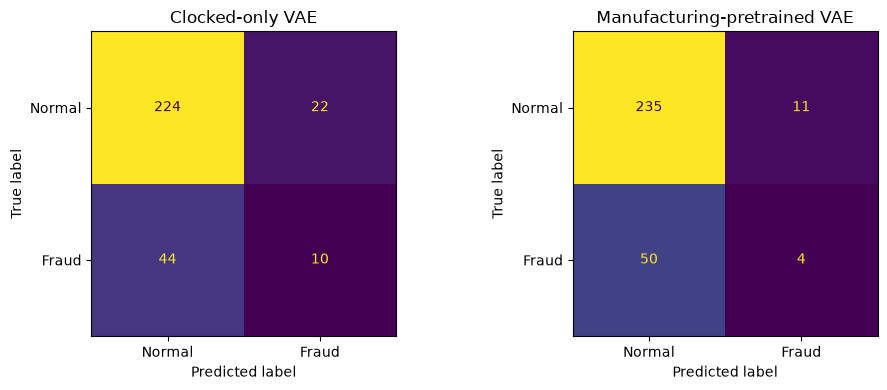

In [15]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4),
)

ConfusionMatrixDisplay(
    confusion_matrix(
        y_clocked_test,
        baseline_result["Prediction"],
    ),
    display_labels=["Normal", "Fraud"],
).plot(
    ax=axes[0],
    colorbar=False,
)

axes[0].set_title("Clocked-only VAE")

ConfusionMatrixDisplay(
    confusion_matrix(
        y_clocked_test,
        pretrained_result["Prediction"],
    ),
    display_labels=["Normal", "Fraud"],
).plot(
    ax=axes[1],
    colorbar=False,
)

axes[1].set_title(
    "Manufacturing-pretrained VAE"
)

plt.tight_layout()
plt.show()
